In [49]:
import numpy as np
import pandas as pd
import anndata as ad
import scipy.io
from scipy.sparse import lil_matrix

# ─────────────────────────────────────────────
# 1. LOAD DATA
# ─────────────────────────────────────────────
BASE = "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline"

adata = ad.read_h5ad(f"{BASE}/velten_rna.h5ad")
X_full = adata.X.toarray() if hasattr(adata.X, "toarray") else adata.X

gene_names = np.array(adata.var_names)
g2i = {g: i for i, g in enumerate(gene_names)}

# TFs
tf_names = np.array(
    open(f"{BASE}/tf_names.txt").read().strip().split()
)

# ─────────────────────────────────────────────
# 2. DEFINE SHARED GENE + TF SPACE
# ─────────────────────────────────────────────

peak_gene = pd.read_csv(f"{BASE}/peak_gene.csv", sep="\t")

genes_used = sorted(set(peak_gene["gene"]) & set(gene_names))
tfs_used   = sorted(set(tf_names) & set(gene_names))  # IMPORTANT: RNA-intersected TFs only

gene_idx = np.array([g2i[g] for g in genes_used])
tf_idx   = np.array([g2i[t] for t in tfs_used])

X    = X_full[:, gene_idx]   # (cells, G)
X_TF = X_full[:, tf_idx]     # (cells, T)

G, T = X.shape[1], X_TF.shape[1]

print("X:", X.shape)
print("X_TF:", X_TF.shape)

# mappings (ONLY ONCE)
gene2i = {g: i for i, g in enumerate(genes_used)}
tf2i   = {t: i for i, t in enumerate(tfs_used)}

# ─────────────────────────────────────────────
# 3. BUILD PEAK → GENE MAP (CLEAN)
# ─────────────────────────────────────────────

peaks = pd.read_csv(f"{BASE}/peaks.txt", header=None)[0].astype(str).tolist()
peak2i = {p: i for i, p in enumerate(peaks)}

P = len(peaks)

peak_gene_mat = lil_matrix((P, G))

for _, row in peak_gene.iterrows():
    p, g = row["peak"], row["gene"]
    if p in peak2i and g in gene2i:
        peak_gene_mat[peak2i[p], gene2i[g]] = 1

peak_gene_mat = peak_gene_mat.tocsr()

# ─────────────────────────────────────────────
# 4. OPTIONAL: GENE × TF ACCESSIBILITY MATRIX M
# ─────────────────────────────────────────────

peak_tf = scipy.io.mmread(f"{BASE}/peak_tf.mtx").tocsr()

assert peak_tf.shape[0] == len(peaks)

# gene × TF motif
M_full = peak_gene_mat.T @ peak_tf   # (G, motif_TFs)
M_full = (M_full > 0).astype(np.float32)

tf2i_motif = {t: i for i, t in enumerate(tf_names)}

# align ONLY to TFs we kept
tf_cols = np.array([tf2i_motif[t] for t in tfs_used])

M = np.array(M_full[:, tf_cols].todense())

print("M:", M.shape)

# ─────────────────────────────────────────────
# 5. FINAL SANITY CHECKS
# ─────────────────────────────────────────────

assert X.shape[1] == G
assert X_TF.shape[1] == T
assert M.shape == (G, T)

print("✓ Pipeline consistent and aligned")

X: (1035, 11483)
X_TF: (1035, 277)
M: (11483, 277)
✓ Pipeline consistent and aligned


In [50]:
# ─────────────────────────────────────────────
# 5. TORCH CONVERSION (CLEAN)
# ─────────────────────────────────────────────

import torch

X_t    = torch.tensor(X, dtype=torch.float32)
X_TF_t = torch.tensor(X_TF, dtype=torch.float32)

print("Torch tensors:")
print("X_t   :", X_t.shape)
print("X_TF_t:", X_TF_t.shape)

# ─────────────────────────────────────────────
# 6. NEAREST NEIGHBORS (OPTIONAL STRUCTURE ONLY)
# ─────────────────────────────────────────────

from sklearn.neighbors import NearestNeighbors

# NOTE:
# This is ONLY for optional smoothness regularization.
# It does NOT define supervision or velocity.

nn_mdl = NearestNeighbors(n_neighbors=30)
nn_idx = nn_mdl.fit(X).kneighbors(X, return_distance=False)

nn_idx_t = torch.tensor(nn_idx, dtype=torch.long)

print("nn_idx_t:", nn_idx_t.shape)

Torch tensors:
X_t   : torch.Size([1035, 11483])
X_TF_t: torch.Size([1035, 277])
nn_idx_t: torch.Size([1035, 30])


In [51]:
# ─────────────────────────────────────────────
# LOAD ATAC (cells x peaks)
# ─────────────────────────────────────────────

from scipy.io import mmread
import numpy as np
import pandas as pd
from sklearn.decomposition import TruncatedSVD
import torch

print("Loading ATAC...")

atac_raw = mmread(f"{BASE}/GSE129785_scATAC-Hematopoiesis-CD34.mtx.gz").tocsr()
atac_X = atac_raw.tocsr().astype(np.float32)

print("atac_X:", atac_X.shape)


# ─────────────────────────────────────────────
# ATAC LSI (MODEL INPUT)
# ─────────────────────────────────────────────

print("Computing ATAC LSI...")

# optional but recommended: TF-IDF style normalization
row_sum = np.array(atac_X.sum(axis=1)).flatten() + 1e-8
atac_tf = atac_X.multiply(1.0 / row_sum[:, None])
atac_tf.data = np.log1p(atac_tf.data * 1e4)

svd = TruncatedSVD(n_components=50, random_state=42)
atac_lsi = svd.fit_transform(atac_tf)

atac_t = torch.tensor(atac_lsi, dtype=torch.float32)

print("atac_t:", atac_t.shape)
assert atac_lsi.shape[0] == X.shape[0], \
    f"Cell mismatch: ATAC={atac_lsi.shape[0]} RNA={X.shape[0]}" # want (1035, 50)

Loading ATAC...
atac_X: (571389, 18489)
Computing ATAC LSI...
atac_t: torch.Size([571389, 50])


AssertionError: Cell mismatch: ATAC=571389 RNA=1035

In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

class TF_Lag(nn.Module):
    """
    Approximates X_TF(t - tau) using exponential moving average.
    This introduces causal asymmetry without needing real timepoints.
    """
    def __init__(self, T, alpha=0.9):
        super().__init__()
        self.alpha = alpha
        self.register_buffer("state", None)

    def forward(self, X_TF):
        # X_TF: (N, T)

        if self.state is None:
            self.state = X_TF.detach().clone()

        # EMA lag approximation
        self.state = self.alpha * self.state + (1 - self.alpha) * X_TF.detach()

        return self.state

In [ ]:
class GRNVelocityModel(nn.Module):
    def __init__(self, G, T, n_lsi):
        super().__init__()

        self.A_base = nn.Parameter(torch.randn(G, T) * 0.01)

        # optional ATAC gate (you already had this)
        self.gate = nn.Linear(n_lsi, T)

        # NEW: lag model
        self.tf_lag = TF_Lag(T)

        # NEW: decay term (important for stability)
        self.decay = nn.Parameter(torch.tensor(0.1))

    def forward(self, X, X_TF, atac, dt=0.1):

        # ─────────────────────────────
        # 1. lagged TF signal (causal asymmetry)
        # ─────────────────────────────
        X_TF_lag = self.tf_lag(X_TF)   # approximates X_TF(t - τ)

        # ─────────────────────────────
        # 2. GRN velocity
        # ─────────────────────────────
        V_grn = X_TF_lag @ self.A_base.T   # (N, G)

        # ─────────────────────────────
        # 3. decay / relaxation term (stabilizes direction)
        # ─────────────────────────────
        V = V_grn - self.decay * X

        # ─────────────────────────────
        # 4. Euler step
        # ─────────────────────────────
        X_pred = X + dt * V

        return V, X_pred

In [ ]:
import torch.nn.functional as F

def flow_loss(model, X, X_TF, atac,
              dt=0.1,
              lambda_l1=1e-3,
              lambda_vel=1e-3,
              lambda_ot=1.0):

    V, X_pred = model(X, X_TF, atac, dt)

    # ─────────────────────────────
    # 1. velocity regularization (stability only)
    # ─────────────────────────────
    loss_vel = V.pow(2).mean()

    # ─────────────────────────────
    # 2. reconstruction consistency (local Euler correctness)
    # ─────────────────────────────
    loss_step = F.mse_loss(X_pred, X)

    # ─────────────────────────────
    # 3. sparse GRN (biological prior)
    # ─────────────────────────────
    loss_l1 = model.A_base.abs().mean()

    total = (
        loss_step
        + lambda_vel * loss_vel
        + lambda_l1 * loss_l1
    )

    return total, {
        "step": loss_step.item(),
        "vel": loss_vel.item(),
        "l1": loss_l1.item()
    }

In [ ]:
from tqdm import trange
import time

def train(model, X, X_TF, atac, nn_idx,
          epochs=200, lr=1e-3):

    opt = torch.optim.Adam(model.parameters(), lr=lr)

    start = time.time()

    for epoch in trange(epochs):

        opt.zero_grad()

        loss, parts = flow_loss(model, X, X_TF, atac, nn_idx)

        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()

        if epoch % 10 == 0:
            dt = time.time() - start
            print(
                f"\nEpoch {epoch} | loss={loss.item():.4f} | "
                f"step={parts['step']:.4f} dir={parts['dir']:.4f}"
            )

    return model

In [ ]:
G = X_t.shape[1]
T = X_TF_t.shape[1]
n_lsi = atac_t.shape[1]

model = GRNVelocityModel(G, T, n_lsi)

model = train(model, X_t, X_TF_t, atac_t, nn_idx_t)

In [36]:
with torch.no_grad():
    V_pred, _ = model(X_t, X_TF_t, atac_t)

np.save("actually_learn_velocity/V_pred.npy", V_pred.cpu().numpy())
np.save("actually_learn_velocity/A.npy", model.A_base.detach().cpu().numpy())
np.save("actually_learn_velocity/gene_names.npy", gene_names)
np.save("actually_learn_velocity/gene_idx.npy", gene_idx)
np.save("actually_learn_velocity/tf_idx.npy", tf_idx)
np.save("actually_learn_velocityX_used.npy", X)
np.save("actually_learn_velocityX_TF_used.npy", X_TF)
np.save("actually_learn_velocity/atac_lsi.npy", atac_lsi)
np.save("actually_learn_velocity/genes_used.npy", np.array(genes_used))

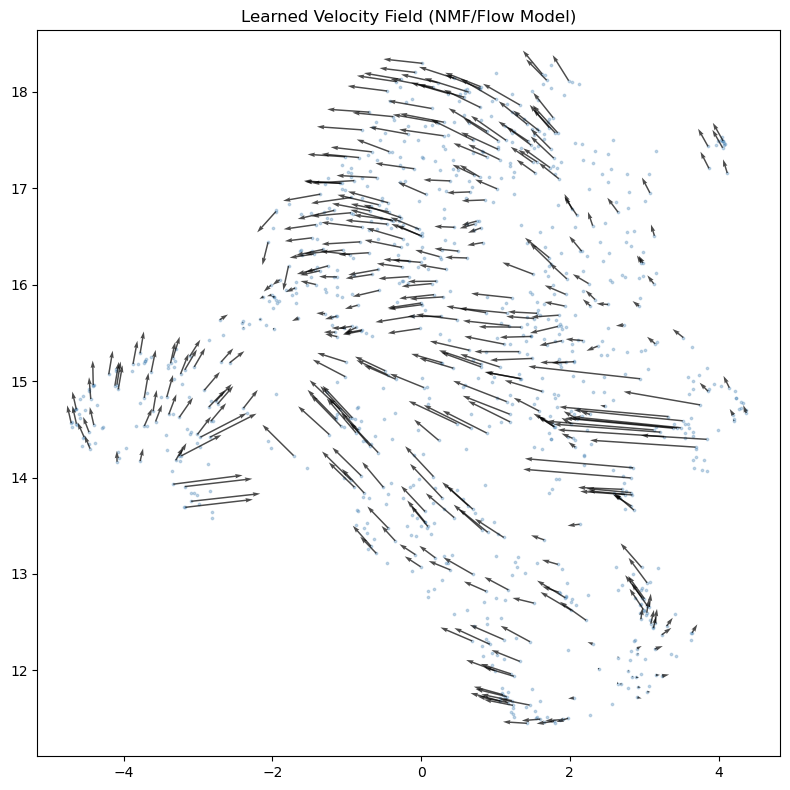

Velocity–pseudotime alignment: -0.046235018302854224


In [40]:
# visualize_velocity.py (UPDATED FOR LEARNED MODEL)

import numpy as np
import anndata as ad
import matplotlib.pyplot as plt
from sklearn.neighbors import NearestNeighbors
from umap import UMAP
from scipy.stats import spearmanr

# =========================
# 1. LOAD DATA
# =========================
import numpy as np
import anndata as ad

adata = ad.read_h5ad(
    "/home/sc5625/cll_project/decipher_atac_project/m_atac_pipeline/velten_rna.h5ad"
)

V_pred = np.load("actually_learn_velocity/V_pred.npy")

gene_names = np.load("actually_learn_velocity/genes_used.npy", allow_pickle=True)

gene_map = {g: i for i, g in enumerate(adata.var_names)}
gene_idx = np.array([gene_map[g] for g in gene_names])
X = adata.X[:, gene_idx]

assert X.shape == V_pred.shape

# =========================
# 3. UMAP EMBEDDING
# =========================
reducer = UMAP(n_neighbors=15, random_state=42)
X_umap = reducer.fit_transform(X)

# =========================
# 4. PROJECT VELOCITY TO UMAP
# =========================
X = adata.X.toarray() if hasattr(adata.X, "toarray") else np.asarray(adata.X)
X = X[:, gene_idx]

# ensure arrays
X = np.asarray(X)
V_pred = np.asarray(V_pred)

eps = 0.5
X_perturbed = X + eps * V_pred
X_pert_umap = reducer.transform(X_perturbed)

V_umap_raw = (X_pert_umap - X_umap) / eps

# =========================
# 5. SMOOTH VELOCITY FIELD
# =========================
nn = NearestNeighbors(n_neighbors=30).fit(X_umap)
_, idx = nn.kneighbors(X_umap)

V_umap_smooth = np.array([
    V_umap_raw[idx[i]].mean(axis=0)
    for i in range(len(X_umap))
])

# =========================
# 6. PLOT VECTOR FIELD
# =========================
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    X_umap[:, 0], X_umap[:, 1],
    s=3, alpha=0.3, c="steelblue"
)

sample = np.random.choice(len(X_umap), 400, replace=False)

ax.quiver(
    X_umap[sample, 0], X_umap[sample, 1],
    V_umap_smooth[sample, 0], V_umap_smooth[sample, 1],
    alpha=0.7, scale=10, width=0.002, color="black"
)

ax.set_title("Learned Velocity Field (NMF/Flow Model)")
plt.tight_layout()
plt.savefig("velocity_final.png", dpi=150)
plt.show()

# =========================================================
# 7. FIXED CORRELATION (IMPORTANT — YOUR OLD ONE WAS WRONG)
# =========================================================

# WRONG BEFORE:
# spearmanr(pseudotime, dot(V, X[i+1] - X[i]))

# CORRECT IDEA:
# does velocity align with actual transitions in pseudotime ordering?

pseudo = adata.obs["facs_pseudotime"].values

# sort by pseudotime
order = np.argsort(pseudo)

X_sorted = X[order]
V_sorted = V_pred[order]

# finite differences along trajectory
dX = X_sorted[1:] - X_sorted[:-1]
V_mid = V_sorted[:-1]

# alignment score (cosine-like dot product)
alignment = np.sum(V_mid * dX, axis=1)

score = spearmanr(pseudo[order][:-1], alignment)[0]

print("Velocity–pseudotime alignment:", score)

In [35]:
print("X original:", adata.X.shape)
print("V_pred:", V_pred.shape)
print("gene_names:", len(gene_names))
print("adata genes:", len(adata.var_names))

missing = [g for g in gene_names if g not in adata.var_names]
print("Missing genes:", len(missing))
print(missing[:20])


X original: (1035, 12553)
V_pred: (1035, 11483)
gene_names: 12553
adata genes: 12553
Missing genes: 0
[]


In [41]:
# Metrics

from sklearn.metrics import r2_score
from scipy.stats import spearmanr
import scvelo as scv

# Metric A: Cross-boundary direction correctness (CBDir)
# Requires cell type labels. Measures whether velocity points from 
# progenitor clusters toward differentiated clusters.

adata.uns.pop("diffmap_evals", None)
adata.obsm.pop("X_diffmap", None)

# scv.tl.velocity_graph(adata)  # uses your V_pred stored in adata.layers['velocity']
# scv.tl.velocity_confidence(adata)
# print(adata.obs['velocity_confidence'].mean())  # higher = more consistent field

# Metric B: velocity graph transition entropy
# A good velocity field should produce low-entropy transitions 
# (cells confidently point one direction, not scattered)
# scv.tl.velocity_graph(adata)
# Inspect adata.uns['velocity_graph'] — row entropy tells you confidence

# Metric C: correlation with RNA-based pseudotime (DPT) 
# as an internal consistency check separate from FACS
from scipy.stats import spearmanr
dpt_corr = spearmanr(adata.obs['dpt_pseudotime'], 
                      adata.obs['facs_pseudotime'])[0]
print("DPT-FACS agreement:", dpt_corr)  # sanity check your pseudotime labels

# Metric D: per-cell consistency (your best unsupervised metric)
# Does velocity at cell i agree with velocity at its neighbors?
def velocity_consistency(V_pred, nn_idx):
    scores = []
    for i in range(len(V_pred)):
        nbr_v = V_pred[nn_idx[i]]  # (K, G)
        v_i = V_pred[i]            # (G,)
        cos = (nbr_v @ v_i) / (
            np.linalg.norm(nbr_v, axis=1) * np.linalg.norm(v_i) + 1e-8
        )
        scores.append(cos.mean())
    return np.array(scores)

consistency = velocity_consistency(V_pred, idx)
print("Mean velocity consistency:", consistency.mean())
# This is fully unsupervised — no pseudotime needed

DPT-FACS agreement: 0.39182819939137054
Mean velocity consistency: 0.87074214
